# 05 · Conversión de anotaciones revisadas (CVAT) a YOLO-pose

**Objetivo:** convertir las anotaciones de keypoints revisadas manualmente en CVAT (formato COCO Keypoints) de vuelta al formato YOLO-pose, generando el dataset de Bundesliga listo para el fine-tuning.

**Contexto:** tras revisar y corregir los 120 frames en CVAT, las anotaciones se exportaron en COCO Keypoints. Este notebook las convierte a YOLO-pose y organiza el dataset en train/valid para el fine-tuning del modelo de keypoints.

**Entrada:** `person_keypoints_default.json` exportado de CVAT y las imágenes en `data/cvat_import/images/`.

**Salida:** dataset YOLO-pose en `data/bundesliga_keypoints/`.

In [1]:
import json
import shutil
import random
from pathlib import Path

REPO_ROOT = Path("../..").resolve()

# Ruta al JSON exportado de CVAT (ajusta si está en otro sitio)
COCO_JSON = Path(r"C:\Users\sgghu\Downloads\annotations\person_keypoints_default.json")

# Imágenes originales (las que subiste a CVAT)
IMAGES_SRC = REPO_ROOT / "data" / "cvat_import" / "images"

# Salida
OUTPUT_DIR = REPO_ROOT / "data" / "bundesliga_keypoints"

N_KP = 24
VAL_SPLIT = 0.2  # 20% para validación

print(f"JSON COCO: {COCO_JSON}")
print(f"¿Existe?: {COCO_JSON.exists()}")
print(f"Imágenes origen: {IMAGES_SRC}")
print(f"¿Existe?: {IMAGES_SRC.exists()}")

JSON COCO: C:\Users\sgghu\Downloads\annotations\person_keypoints_default.json
¿Existe?: True
Imágenes origen: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\cvat_import\images
¿Existe?: True


In [2]:
with open(COCO_JSON, encoding="utf-8") as f:
    coco = json.load(f)

print(f"Imágenes en el JSON: {len(coco['images'])}")
print(f"Anotaciones en el JSON: {len(coco['annotations'])}")

# Mapa de image_id -> info de imagen
img_info = {img["id"]: img for img in coco["images"]}

# Verificar estructura de una anotación
if coco["annotations"]:
    ej = coco["annotations"][0]
    print(f"\nEjemplo de anotación:")
    print(f"  image_id: {ej['image_id']}")
    print(f"  num_keypoints: {ej.get('num_keypoints')}")
    print(f"  longitud keypoints: {len(ej['keypoints'])} (esperado {N_KP*3})")

Imágenes en el JSON: 120
Anotaciones en el JSON: 120

Ejemplo de anotación:
  image_id: 1
  num_keypoints: 5
  longitud keypoints: 72 (esperado 72)


## Conversión a YOLO-pose

Para cada anotación se convierten los keypoints de píxeles absolutos (COCO) a coordenadas normalizadas 0-1 (YOLO). La visibilidad de CVAT (0=no marcado, 1=oculto, 2=visible) se mapea a la de YOLO (0=no visible, 2=visible).

In [3]:
# Crear estructura de salida
for split in ["train", "valid"]:
    (OUTPUT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

# Agrupar anotaciones por imagen
ann_por_img = {}
for ann in coco["annotations"]:
    ann_por_img.setdefault(ann["image_id"], []).append(ann)

# Lista de imágenes con anotación, para repartir en train/valid
img_ids = list(ann_por_img.keys())
random.seed(42)
random.shuffle(img_ids)
n_val = int(len(img_ids) * VAL_SPLIT)
val_ids = set(img_ids[:n_val])

procesados = {"train": 0, "valid": 0}
no_encontradas = 0

for img_id, anns in ann_por_img.items():
    info = img_info[img_id]
    w, h = info["width"], info["height"]
    fname = info["file_name"]

    # Algunas exportaciones anteponen rutas; nos quedamos con el nombre base
    fname_base = Path(fname).name
    src_img = IMAGES_SRC / fname_base
    if not src_img.exists():
        no_encontradas += 1
        continue

    split = "valid" if img_id in val_ids else "train"

    # Tomamos la primera anotación (un campo por imagen)
    ann = anns[0]
    kps = ann["keypoints"]

    partes = ["0", "0.5", "0.5", "1.0", "1.0"]
    for i in range(N_KP):
        x, y, v = kps[i*3], kps[i*3+1], kps[i*3+2]
        if v >= 2:  # visible
            partes.extend([f"{x/w:.6f}", f"{y/h:.6f}", "2"])
        else:        # no visible / oculto
            partes.extend(["0", "0", "0"])

    # Guardar imagen y etiqueta
    shutil.copy2(src_img, OUTPUT_DIR / split / "images" / fname_base)
    label_name = Path(fname_base).stem + ".txt"
    with open(OUTPUT_DIR / split / "labels" / label_name, "w") as f:
        f.write(" ".join(partes) + "\n")

    procesados[split] += 1

print(f"Train: {procesados['train']} imágenes")
print(f"Valid: {procesados['valid']} imágenes")
print(f"Imágenes no encontradas: {no_encontradas}")

Train: 96 imágenes
Valid: 24 imágenes
Imágenes no encontradas: 0


In [4]:
# Crear data.yaml para el fine-tuning
KEYPOINT_NAMES = [
    "corner_inf_izq", "corner_sup_izq", "corner_inf_der", "corner_sup_der",
    "area_grande_izq_inf", "area_grande_izq_sup", "area_grande_der_inf", "area_grande_der_sup",
    "area_peq_izq_inf", "area_peq_izq_sup", "area_peq_der_inf", "area_peq_der_sup",
    "penalti_izq", "penalti_der", "centro", "media_inf", "media_sup",
    "fondo_izq_area_inf", "fondo_izq_area_sup", "fondo_der_area_inf",
    "poste_izq_inf", "poste_izq_sup", "poste_der_inf", "poste_der_sup",
]

yaml_content = f"""train: {OUTPUT_DIR}/train/images
val: {OUTPUT_DIR}/valid/images

kpt_shape: [24, 3]
nc: 1
names: ['field']
"""

yaml_path = OUTPUT_DIR / "data.yaml"
with open(yaml_path, "w", encoding="utf-8") as f:
    f.write(yaml_content)

print("data.yaml creado:\n")
print(yaml_content)

data.yaml creado:

train: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\bundesliga_keypoints/train/images
val: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\bundesliga_keypoints/valid/images

kpt_shape: [24, 3]
nc: 1
names: ['field']



Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\verificacion_bundesliga_keypoints.png


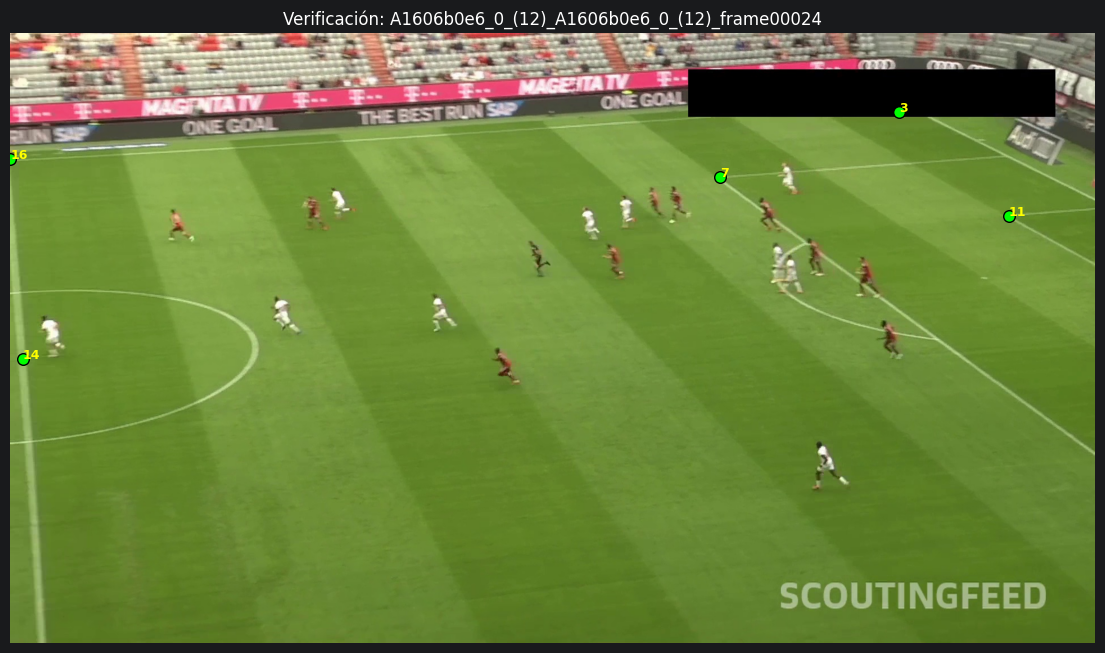

In [5]:
# Verificación visual de una etiqueta convertida
import matplotlib.pyplot as plt
import cv2

train_labels = list((OUTPUT_DIR / "train" / "labels").glob("*.txt"))
ejemplo = train_labels[0]
img_path = OUTPUT_DIR / "train" / "images" / (ejemplo.stem + ".jpg")

with open(ejemplo) as f:
    vals = f.read().split()
kps = vals[5:]

img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

plt.figure(figsize=(14, 8))
plt.imshow(img)
for i in range(N_KP):
    x, y, v = kps[i*3:i*3+3]
    if int(v) == 2:
        plt.scatter(float(x)*w, float(y)*h, c="lime", s=70, edgecolors="black", zorder=3)
        plt.annotate(str(i), (float(x)*w, float(y)*h), color="yellow", fontsize=9, fontweight="bold")
plt.title(f"Verificación: {ejemplo.stem}")
plt.axis("off")
output_fig = REPO_ROOT / "outputs" / "verificacion_bundesliga_keypoints.png"
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()